# 02 – Phân tích CHẨN ĐOÁN (TV3)

Logic nằm ở `src/diagnose.py`. **Giả thuyết H7 (viết trước khi chạy, `docs/A_gia_thuyet.md`):** tương quan đôi trung bình giữa các mã trong 2022 **cao hơn** giai đoạn "bình thường" (11/2018–12/2021). Quy tắc bác bỏ: khoảng 95% của hiệu (2022 − bình thường) chứa 0 hoặc âm.

**Phương pháp:** tương quan Pearson trung bình của các cặp mã (lợi suất ngày) trên 28 mã có ≥95% phiên ở cả hai giai đoạn (ROS ngừng giao dịch giữa 2022 nên bị loại khỏi phép so sánh); bootstrap khối trượt 20 phiên, lấy mẫu riêng trong từng giai đoạn, B = 5.000, hạt giống từ `config.yaml`. Báo thêm tỷ lệ phương sai của thành phần chính thứ nhất (PC1) và độ nhạy theo độ dài khối.

**Diễn giải:** đây là *liên hệ*, không phải nhân quả; 2022 chỉ là một giai đoạn.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent            # notebook nằm trong notebooks/
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
from IPython.display import Image, display
import describe
import diagnose
pd.set_option("display.width", 200, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
FIG = ROOT / "outputs" / "figures"

In [2]:
out = diagnose.run()
print("Số mã so sánh:", len(out["assets"]))

Số mã so sánh: 28


## 1. Kiểm định tương quan 2022 so với giai đoạn bình thường

In [3]:
t = out["test"]
cols = ["thong_ke", "do_dai_khoi", "binh_thuong", "nam_2022", "hieu_2022_tru_binh_thuong", "ci95_thap", "ci95_cao", "p_mot_phia_hieu_le_0", "ket_luan_H7"]
display(t[cols])

,thong_ke,do_dai_khoi,binh_thuong,nam_2022,hieu_2022_tru_binh_thuong,ci95_thap,ci95_cao,p_mot_phia_hieu_le_0,ket_luan_H7
0,tuong_quan_trung_binh,5,0.3696,0.3733,0.0037,-0.0713,0.0823,0.4424,khong_ung_ho (khoang 95% chua 0 hoac am)
1,tuong_quan_trung_binh,10,0.3696,0.3733,0.0037,-0.0813,0.0903,0.4504,khong_ung_ho (khoang 95% chua 0 hoac am)
2,tuong_quan_trung_binh,20,0.3696,0.3733,0.0037,-0.0892,0.1073,0.4366,khong_ung_ho (khoang 95% chua 0 hoac am)
3,tuong_quan_trung_binh,40,0.3696,0.3733,0.0037,-0.0983,0.1160,0.4170,khong_ung_ho (khoang 95% chua 0 hoac am)
4,ty_le_PC1,5,0.4120,0.4238,0.0118,-0.0575,0.0868,0.3444,khong_ung_ho (khoang 95% chua 0 hoac am)
5,ty_le_PC1,10,0.4120,0.4238,0.0118,-0.0659,0.0949,0.3620,khong_ung_ho (khoang 95% chua 0 hoac am)
6,ty_le_PC1,20,0.4120,0.4238,0.0118,-0.0736,0.1098,0.3546,khong_ung_ho (khoang 95% chua 0 hoac am)
7,ty_le_PC1,40,0.4120,0.4238,0.0118,-0.0849,0.1178,0.3614,khong_ung_ho (khoang 95% chua 0 hoac am)


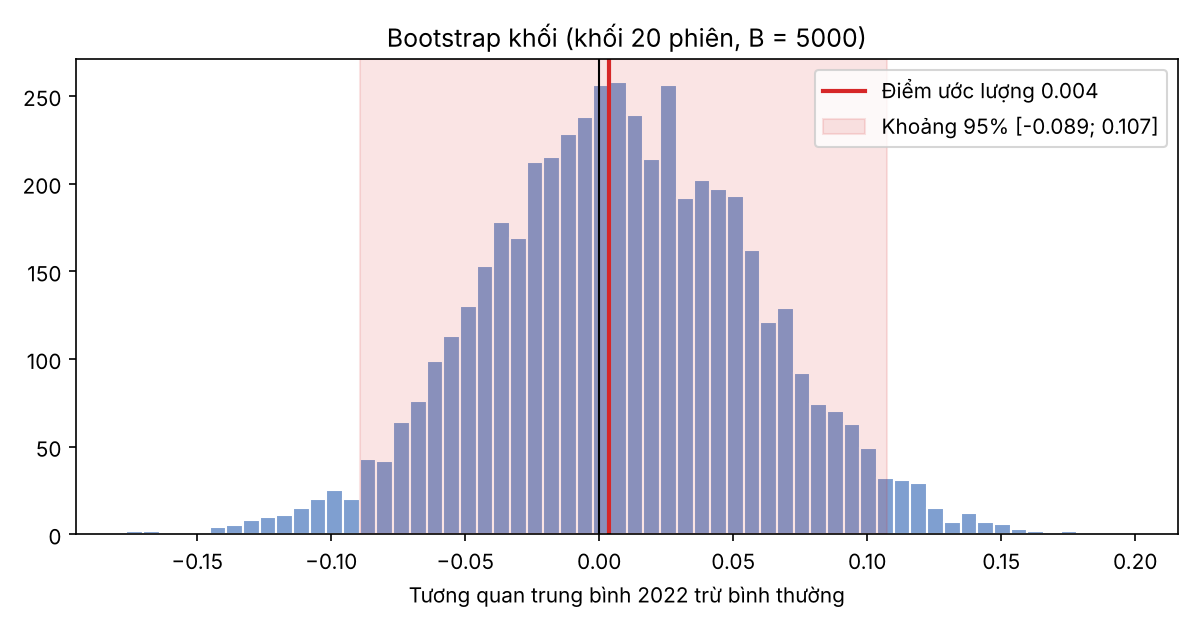

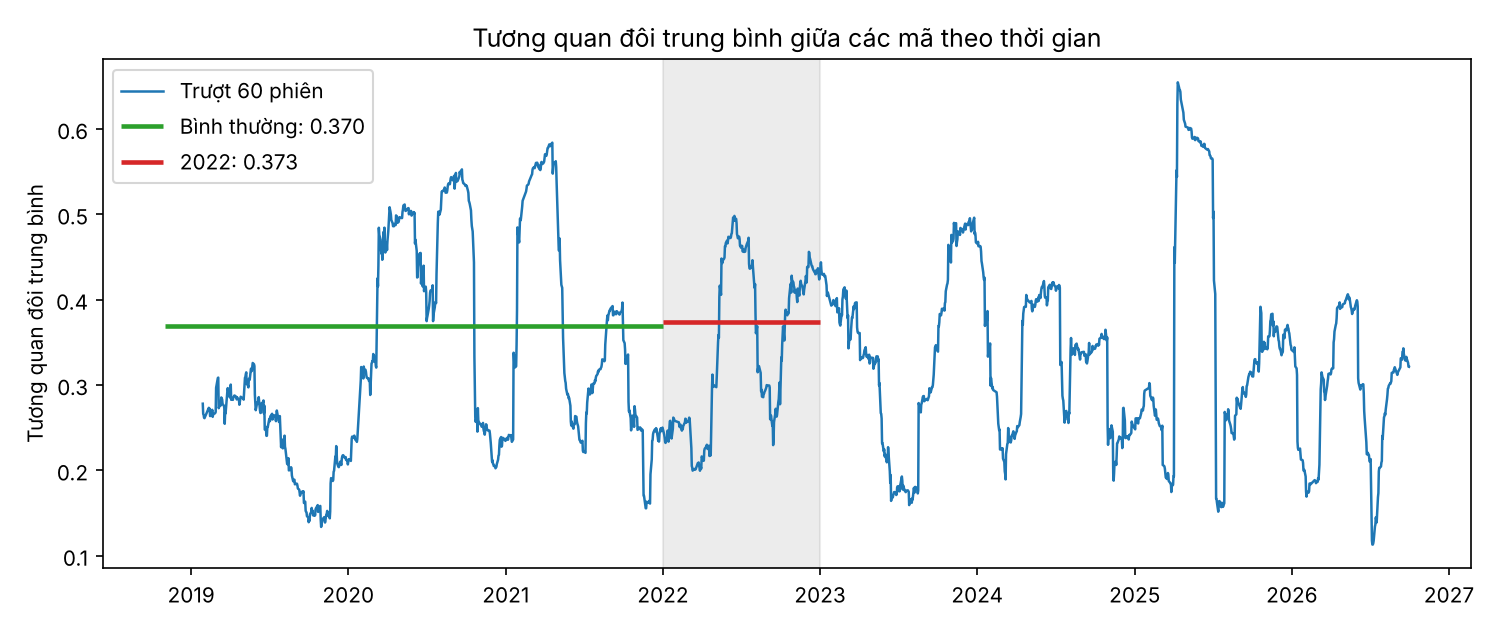

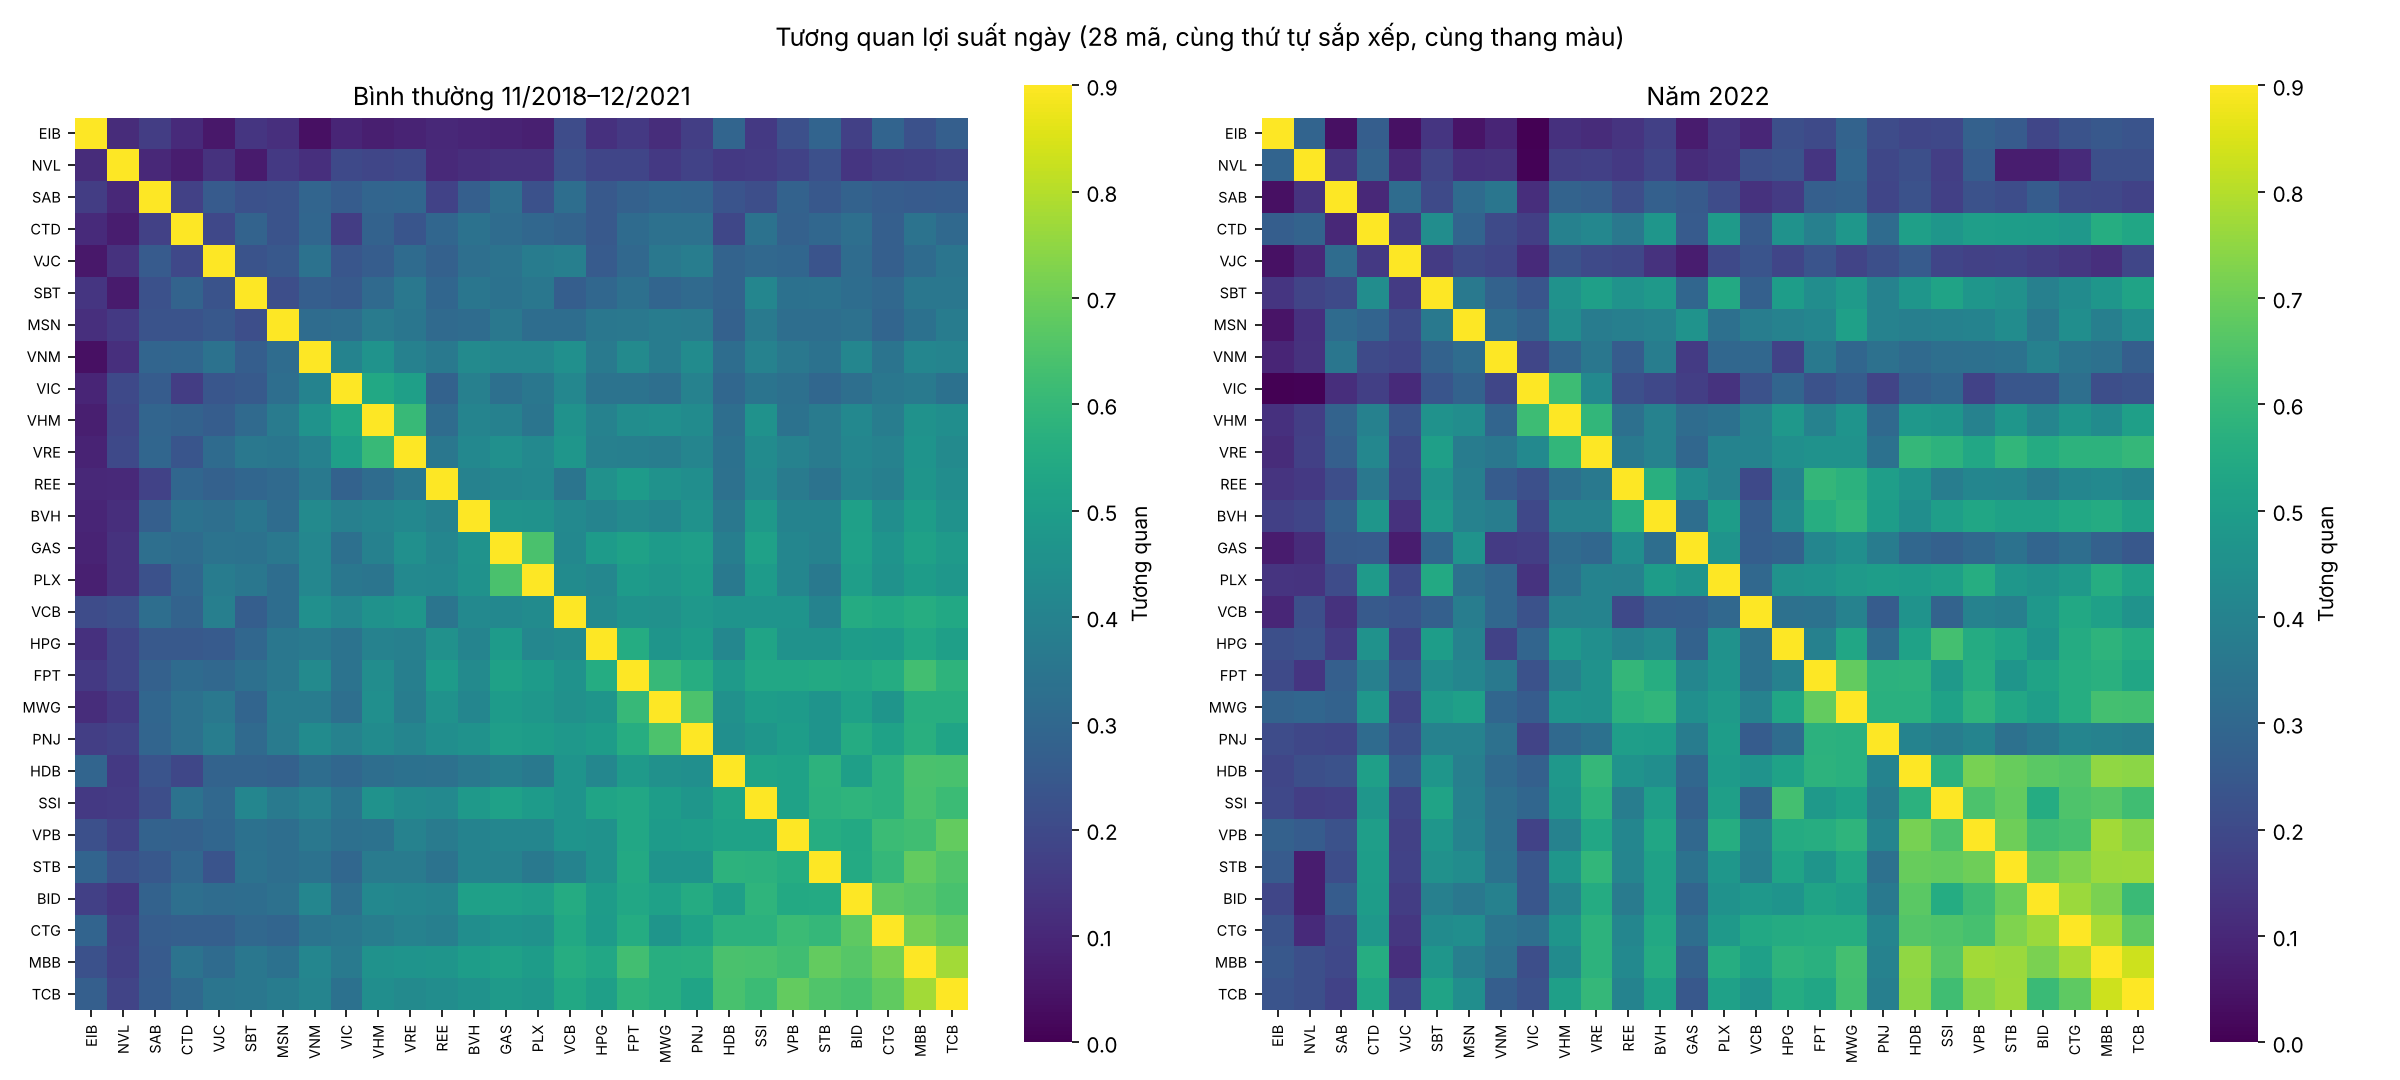

In [4]:
display(Image(FIG / "chan_doan_bootstrap.png"))
display(Image(FIG / "chan_doan_tuong_quan_theo_thoi_gian.png"))
display(Image(FIG / "chan_doan_heatmap_2_giai_doan.png"))

**Kết quả: giả thuyết H7 KHÔNG được ủng hộ.**
- Tương quan đôi trung bình: 0,370 (bình thường) so với 0,373 (2022); hiệu +0,004, khoảng 95% [−0,09; +0,11] (khối 20 phiên) chứa 0. Kết luận không đổi với khối 5, 10, 40 phiên và với tỷ lệ PC1 (0,412 so với 0,424; khoảng chứa 0).
- Hình theo thời gian cho thấy lý do: tương quan trượt 60 phiên dao động mạnh trong **mọi** giai đoạn (từ khoảng 0,1 đến 0,65). Giai đoạn "bình thường" đã chứa đợt COVID 2020 và các nhịp 2021 có tương quan cao nên mức trung bình của nó không thấp.

### Phép thử độ nhạy (làm THÊM sau khi thấy kết quả chính, không thay thế H7)

In [5]:
tc = out["test_covid"]
display(tc[["bien_the", "thong_ke", "binh_thuong", "nam_2022", "hieu_2022_tru_binh_thuong", "ci95_thap", "ci95_cao", "ket_luan_H7"]])
display(out["context"])

,bien_the,thong_ke,binh_thuong,nam_2022,hieu_2022_tru_binh_thuong,ci95_thap,ci95_cao,ket_luan_H7
0,tham_do_bo_02-04/2020,tuong_quan_trung_binh,0.3409,0.3733,0.0324,-0.0713,0.1355,khong_ung_ho (khoang 95% chua 0 hoac am)
1,tham_do_bo_02-04/2020,ty_le_PC1,0.3829,0.4238,0.0409,-0.0548,0.1387,khong_ung_ho (khoang 95% chua 0 hoac am)


,giai_doan,tuong_quan_trung_binh_co_ROS,so_ma,bien_dong_nam_tb_ma,bien_dong_nam_vnindex,loi_suat_tb_ngay_vnindex
0,binh_thuong,0.3545,29,0.3166,0.1876,0.0007
1,nam_2022,0.3617,29,0.4115,0.2483,-0.0015


Loại 02–04/2020 khỏi giai đoạn bình thường: hiệu tăng lên +0,032 nhưng khoảng 95% [−0,07; +0,14] vẫn chứa 0, nên kết luận không đổi. Đây là phép thử khám phá do nhóm chọn sau khi thấy kết quả, nên chỉ dùng để kiểm tra độ vững, không dùng để "cứu" H7.

**Điều thay đổi rõ trong 2022 là biến động, không phải tương quan:** biến động năm trung bình của từng mã tăng từ 31,7% lên 41,1% và của VN-Index từ 18,8% lên 24,8%, trong khi tương quan trung bình gần như không đổi. Hệ số đa dạng hóa của danh mục 1/N vì thế gần như giữ nguyên (1,59 so với 1,56), còn biến động danh mục tăng từ 20,0% lên 26,4%. Đây là liên hệ mô tả trên một giai đoạn, không phải quy luật.

## 2. Đóng góp rủi ro của từng mã vào danh mục 1/N

,giai_doan,so_phien,so_ma,bien_dong_nam_danh_muc,bien_dong_nam_tb_ma,he_so_da_dang_hoa,tuong_quan_trung_binh,so_ma_chiem_50pct_rui_ro
0,binh_thuong,793,28,0.1995,0.3166,1.5869,0.3696,12
1,nam_2022,249,28,0.2640,0.4115,1.5586,0.3733,11
2,lop1,746,28,0.1874,0.3163,1.6879,0.3351,12


giai_doan,binh_thuong,nam_2022,lop1
ma,,,
SSI,5.1700,5.7500,4.9500
STB,4.6600,5.5500,3.7100
CTD,3.3900,5.1400,4.3200
MWG,3.9300,4.7300,4.4700
MBB,4.4500,4.7100,3.6600
CTG,4.6900,4.7000,3.7700
TCB,4.5700,4.6300,3.9700
BID,4.4900,4.4600,3.5400
HPG,3.9800,4.4400,3.7100


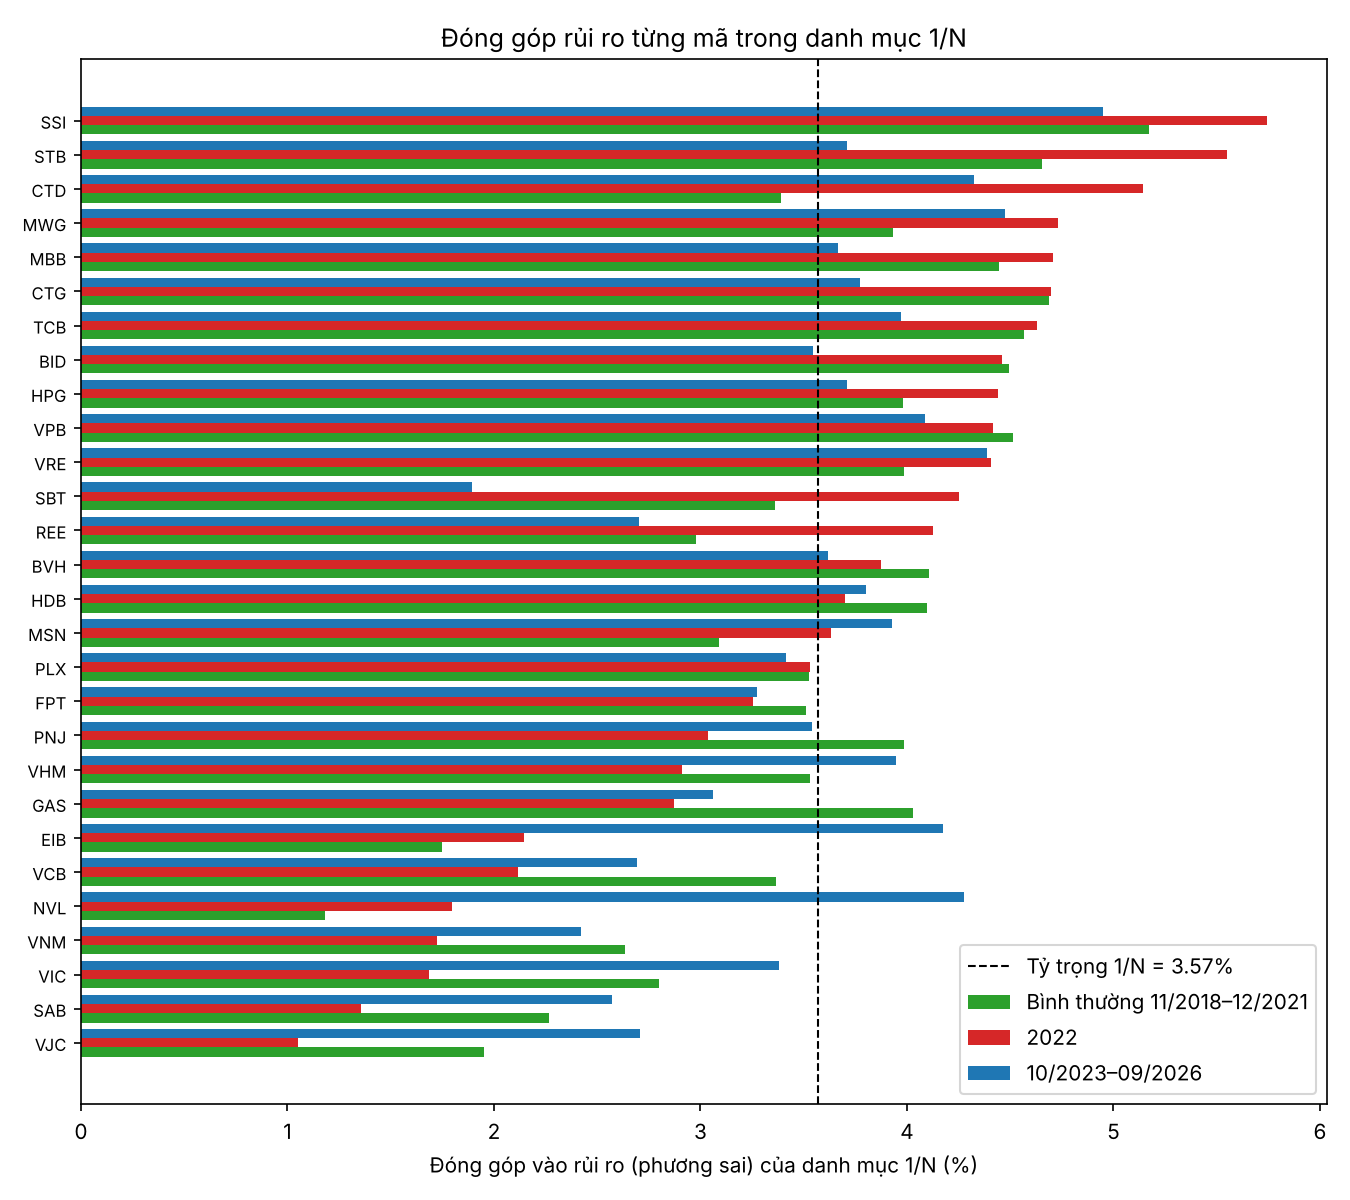

In [6]:
rc = out["rc"]
display(out["portfolio"])
pv = rc.pivot(index="ma", columns="giai_doan", values="dong_gop_rui_ro")[["binh_thuong", "nam_2022", "lop1"]]
display((pv * 100).sort_values("nam_2022", ascending=False).round(2))
display(Image(FIG / "chan_doan_dong_gop_rui_ro.png"))

**Nhận xét:** với tỷ trọng đều 1/28 = 3,57% mỗi mã, đóng góp rủi ro lệch nhau khá nhiều (khoảng 1% đến 5,7%). Năm 2022, SSI (5,7%), STB (5,5%) và CTD (5,1%) đóng góp nhiều nhất; VJC (1,1%), SAB (1,4%), VIC (1,7%) ít nhất. 11–12 mã đầu đã chiếm 50% rủi ro. Nghĩa là 1/N đều về **vốn** nhưng không đều về **rủi ro**; đây là cơ sở để so với Risk Parity (đóng góp rủi ro bằng nhau) ở phần đề xuất.

**Hạn chế:** (1) hiệp phương sai mẫu, 249–793 phiên, có nhiễu ước lượng; (2) tập 28 mã loại ROS ở cả ba giai đoạn để so sánh cùng tập; (3) giai đoạn 2022 nằm trong tập test nhưng phân tích chẩn đoán này không dùng để chọn thiết kế nào; (4) liên hệ ≠ nhân quả.